# 4 · Attention from first principles

**Question.** How can a representation select and combine information relevant to a query?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/04-attention.ipynb)

Attention constructs a weighted average whose weights depend on the current query. For a statistician, normalized kernel weighting is a useful starting analogy. The important differences are that the representations are learned, keys and values can differ, and several attention operations are composed inside a prediction model. This chapter calculates the weights, tests the causal information boundary, and implements multiple heads without hiding the dimensions.

**Prerequisites:** Chapters 2–3, matrix products, and softmax. **Outcomes:** calculate attention by hand; implement stable masked attention; distinguish self-attention from cross-attention; explain what an attention plot can and cannot show.

## Pipeline and framework

![One attention head projects Q, K and V, scales and masks query-key scores, normalizes each row, and multiplies by V; multiple heads are concatenated and projected. Remember: ask with Q, match with K, mix V.](https://chikuang.github.io/teaching/genai/_static/diagrams/04-attention.png)

Read one head from left to right. Each query position requests information, the key vectors determine compatibility, and the value vectors contain what is averaged. The mask specifies which keys a query is allowed to inspect. It acts on scores **before** softmax, not on the already averaged result.

| Operation | Shape in one head | Invariant |
|:--|:--|:--|
| Project | Queries: $T_q \times d_k$; keys: $T_k \times d_k$; values: $T_k \times d_v$ | Key and value rows refer to the same source positions. |
| Score and mask | $QK^T/\sqrt{d_k}$ has shape $T_q \times T_k$. | Disallowed positions cannot receive positive attention mass. |
| Normalize | $A$ has shape $T_q \times T_k$. | Each valid row sums to one; every query needs at least one allowed key. |
| Aggregate | $AV$ has shape $T_q \times d_v$. | Values, not keys, are averaged. |

Self-attention takes all three projections from the same sequence. Cross-attention takes queries from one sequence and keys/values from another. In either case the pipeline is the same. The intervention test in Section 4.5 changes future input positions and checks earlier outputs; this is a stronger implementation check than visually inspecting a triangular matrix.

## 4.1 · Queries, keys, and values

For $n_q$ queries, $n_k$ keys, key width $d_k$, and value width $d_v$, define

$$
Q\in\mathbb R^{n_q\times d_k},\quad
K\in\mathbb R^{n_k\times d_k},\quad
V\in\mathbb R^{n_k\times d_v}.
$$

The score matrix $S=QK^\top/\sqrt{d_k}$ has shape $n_q\times n_k$. A row-wise softmax produces $A$, and the result is $O=AV$ with shape $n_q\times d_v$. Each output row is a convex combination of value rows. It need not be a convex combination of the original token embeddings because the values are themselves projected features.

In self-attention, $Q=XW_Q$, $K=XW_K$, and $V=XW_V$ come from the same sequence. In cross-attention, queries come from one sequence and keys and values from another. The query and key counts need not agree.

### Write the weights entry by entry

Let $\mathcal J_i$ be the nonempty set of key positions available to query $i$. With $q_i,k_j$ as rows of $Q,K$ and $v_j$ a row of $V$,

$$
A_{ij}=\begin{cases}
\displaystyle\frac{\exp(q_i k_j^\top/\sqrt{d_k})}
{\sum_{\ell\in\mathcal J_i}\exp(q_i k_\ell^\top/\sqrt{d_k})},
&j\in\mathcal J_i,\\
0,&j\notin\mathcal J_i,
\end{cases}
\qquad o_i=\sum_{j\in\mathcal J_i}A_{ij}v_j.
$$

Thus $A\in\mathbb R^{n_q\times n_k}$ and $O\in\mathbb R^{n_q\times d_v}$. Equation [(4.1)](https://chikuang.github.io/teaching/genai/chapters/04-attention.html#equation-eq-attention) normalizes each row **over keys for that query**, not over feature coordinates. Causal self-attention sets $\mathcal J_i=\{1,\ldots,i\}$, with padding exclusions if needed. In matrix form this is $A=\operatorname{softmax}_{\mathrm{rows}}(QK^\top/\sqrt{d_k}+M)$, where allowed entries of $M$ are zero and forbidden entries are $-\infty$. An all-masked row has no valid probability distribution.

## 4.2 · Work through three keys

Take a one-dimensional query $q=1$, keys $0,1,2$, and values $10,20,40$. The unnormalized weights are $1,e,e^2$. After division by their sum, the weights are approximately $(0.090,0.245,0.665)$ and the weighted value is approximately $32.405$. The largest score receives the most weight, but the other values still contribute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def softmax(scores):
    shifted = scores - np.max(scores, axis=-1, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=-1, keepdims=True)

q = np.array([[1.]])
k = np.array([[0.], [1.], [2.]])
v = np.array([[10.], [20.], [40.]])
weights = softmax(q @ k.T)
print('Weights:', np.round(weights, 3))
print('Weighted value:', np.round(weights @ v, 3))
assert np.allclose(weights.sum(axis=-1), 1)

Weights: [[0.09  0.245 0.665]]
Weighted value: [[32.405]]


Subtracting the row maximum leaves softmax unchanged but avoids exponentiating unnecessarily large positive numbers. `axis=-1` means normalize across keys for each query. Normalizing over all entries at once would couple unrelated query rows and implement a different operation.

## 4.3 · Why divide by the square root of width?

Suppose the components of a query and a key are independent, mean zero, variance one, and independent across the two vectors. Their dot product has variance $d_k$. Dividing by $\sqrt{d_k}$ gives variance one under these assumptions. Without scaling, increasing width can make initial scores more extreme and softmax more concentrated. Learned features need not satisfy these assumptions exactly; this is an initialization argument, not a universal distributional theorem.

In [2]:
rng = np.random.default_rng(4)
for width in [4, 32, 256]:
    queries = rng.normal(size=(3000, width))
    keys = rng.normal(size=(3000, width))
    dot = (queries * keys).sum(axis=1)
    print(width, 'raw variance', round(dot.var(), 2),
          'scaled variance', round((dot / np.sqrt(width)).var(), 2))

4 raw variance 4.15 scaled variance 1.04
32 raw variance 31.33 scaled variance 0.98
256 raw variance 251.26 scaled variance 0.98


A temperature also rescales logits, but its purpose in decoding is distinct from this architectural width correction. The same mathematical operation can play different roles in different parts of a system.

## 4.4 · Mask before normalizing

A causal language model must not use future tokens when predicting the next token. For query position $i$, allow keys $j\le i$. Put negative infinity in forbidden score entries before softmax; their exponentials become zero. Every row must have at least one allowed key, or normalization is undefined.

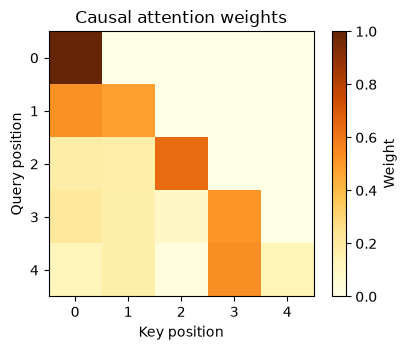

In [3]:
def attention(Q, K, V, allowed=None):
    assert Q.shape[-1] == K.shape[-1]
    assert K.shape[-2] == V.shape[-2]
    scores = Q @ K.T / np.sqrt(Q.shape[-1])
    if allowed is not None:
        assert allowed.shape == scores.shape
        assert np.all(allowed.any(axis=-1)), 'An attention row has no valid keys'
        scores = np.where(allowed, scores, -np.inf)
    A = softmax(scores)
    return A @ V, A

X = rng.normal(size=(5, 4))
Wq, Wk, Wv = [rng.normal(scale=0.4, size=(4, 4)) for _ in range(3)]
causal = np.tril(np.ones((5, 5), dtype=bool))
output, A = attention(X @ Wq, X @ Wk, X @ Wv, causal)
assert np.allclose(A.sum(1), 1)
assert np.all(A[np.triu_indices(5, k=1)] == 0)
fig, ax = plt.subplots(figsize=(4.5, 3.6))
im = ax.imshow(A, cmap='YlOrBr', vmin=0, vmax=1)
ax.set(xlabel='Key position', ylabel='Query position', title='Causal attention weights')
fig.colorbar(im, ax=ax, label='Weight')
plt.tight_layout()
plt.show()

Padding masks solve a different problem: they exclude padded positions. A batch with both causal and padding constraints must combine the allowed-position conditions. Mask conventions differ between software functions, so check whether a boolean `True` means “allow” or “block” before reusing a mask.

## 4.5 · Test causality by intervention

A triangular-looking plot is not a sufficient test of the entire computation. Change a future input and verify that earlier outputs do not change. This probes the information path, not just the mask's appearance.

In [4]:
changed = X.copy()
changed[4] += 20
changed_output, _ = attention(changed @ Wq, changed @ Wk, changed @ Wv, causal)
print('Largest change before final position:', np.abs(changed_output[:4]-output[:4]).max())
assert np.allclose(changed_output[:4], output[:4])
unmasked, _ = attention(X @ Wq, X @ Wk, X @ Wv)
unmasked_changed, _ = attention(changed @ Wq, changed @ Wk, changed @ Wv)
print('Change without mask:', np.linalg.norm(unmasked_changed[:4]-unmasked[:4]))

Largest change before final position: 0.0
Change without mask: 49.02098972693644


This test holds the model parameters fixed. It checks dependence within a forward pass. It does not rule out leakage through duplicated documents, preprocessing, or training on evaluation answers.

## 4.6 · Multiple heads and cross-attention

Different heads use different projections and can form different averages. Their outputs are concatenated and passed through another learned linear map. Heads are not guaranteed to acquire distinct human-interpretable roles.

In [5]:
head_outputs = []
for head in range(2):
    Qh, Kh, Vh = [X @ rng.normal(scale=0.3, size=(4, 2)) for _ in range(3)]
    Oh, _ = attention(Qh, Kh, Vh, causal)
    head_outputs.append(Oh)
concatenated = np.concatenate(head_outputs, axis=-1)
Wo = rng.normal(scale=0.3, size=(4, 4))
print('Concatenated heads:', concatenated.shape)
print('Projected result:', (concatenated @ Wo).shape)

queries = rng.normal(size=(2, 3))
keys = rng.normal(size=(7, 3))
values = rng.normal(size=(7, 4))
cross_output, cross_weights = attention(queries, keys, values)
print('Cross-attention:', cross_weights.shape, '->', cross_output.shape)

Concatenated heads: (5, 4)
Projected result: (5, 4)
Cross-attention: (2, 7) -> (2, 4)


Without positions or a mask, self-attention is permutation equivariant: permuting the input rows permutes the output rows in the same way. That is appropriate for sets, but sequence modeling requires information about order. Chapter 3's positional features and this chapter's causal constraint provide different forms of such information.

### Multiple heads: concatenate, then project

For $h$ self-attention heads on $X\in\mathbb R^{n\times d}$, define

$$
O^{(r)}=\operatorname{Attention}(XW_Q^{(r)},XW_K^{(r)},XW_V^{(r)}),
\quad r=1,\ldots,h,
$$

$$
\operatorname{MHA}(X)=\operatorname{Concat}(O^{(1)},\ldots,O^{(h)})W_O.
$$

Here $W_Q^{(r)},W_K^{(r)}\in\mathbb R^{d\times d_k}$, $W_V^{(r)}\in\mathbb R^{d\times d_v}$, and $W_O\in\mathbb R^{hd_v\times d}$. In Equation [(4.2)](https://chikuang.github.io/teaching/genai/chapters/04-attention.html#equation-eq-multihead), concatenation joins feature columns, not token rows. The examples set $d_k=d_v=d/h$; the final projection restores width $d$. Biases are omitted in this notation but included in the next chapter's linear layers. Cross-attention replaces the key/value input by a separate observed sequence and can have $n_q\ne n_k$.

## 4.7 · What attention weights do not establish

A weight describes one intermediate calculation. The contribution of a value depends on its magnitude and direction, other heads, residual connections, and later nonlinear layers. A large weight is therefore not automatically a faithful explanation of the final prediction. Correlated or interchangeable values can also make weights nonunique explanations of an output.

For a useful diagnostic, compare predictions after controlled changes to inputs, inspect performance on a specified task, and consider the full computation. Even an intervention on model inputs establishes behavior of that model, not a causal effect in the external world.

## 4.8 · Exercises and worked solutions

1. **Equal scores:** if all scores in a row equal $c$, what is the result? **Solution:** each weight is $1/n_k$, so the output is the mean of the values. Adding the same constant to every score never changes a softmax row.
2. **Dimensions:** let $Q$ be $6\times8$, $K$ be $10\times8$, and $V$ be $10\times3$. **Solution:** scores and weights are $6\times10$; output is $6\times3$. A $10\times8$ value matrix is not required.
3. **First causal position:** what can position zero attend to? **Solution:** only itself in our convention. Its attention weight is exactly one. It predicts the next token using the current prefix, not by looking at the next token's representation.
4. **Wrong normalization:** why is applying a mask after softmax generally incorrect? **Solution:** setting forbidden weights to zero afterward makes the allowed weights sum to less than one. Renormalizing could recover the intended result, but masking logits is the direct and stable implementation.
5. **Convexity:** can one output coordinate exceed the largest corresponding value coordinate? **Solution:** not for a single row of $AV$ with nonnegative weights summing to one. The later output projection or residual addition can exceed that range.
6. **Permutation check:** implement a row permutation for unmasked attention and compare outputs. **Solution:** compute both the permuted input result and the original output permuted in the same way; they should agree up to floating-point error. Fixed position features or a causal mask change the symmetry.

## 4.9 · Reading and next step

[Attention Is All You Need](https://arxiv.org/abs/1706.03762) introduces the transformer architecture and scaled dot-product multi-head attention. Our numerical examples expose the weighting and masking operations. [Chapter 5](https://chikuang.github.io/teaching/genai/chapters/05-transformers.html) assembles them with residual connections, normalization, and a prediction head.